In [1]:
import os
os.environ['EMRT_ORIGIN_BINARY'] = "cmake-build-release-gcc/"
os.environ['EMRT_TRACER_BINARY'] = "cmake-build-release-gcc/em_tracer"
os.environ['EMRT_CREEP_BINARY'] = "cmake-build-release-gcc/creep"
os.environ['EMRT_FILLVOLUME_BINARY'] = "cmake-build-release-gcc/"
os.environ['EMRT_CWD'] = "."

import numpy as np
from trimesh.creation import icosphere
from safrac import FractalGenerator
from matplotlib import cm, tri
from matplotlib.colors import LightSource
import matplotlib.pyplot as plt
import numpy as np
from trimesh.base import Trimesh
import trimesh as tm
import json
from pathlib import Path

from landingsite import *
from emrt.input import generate_emrt_input, check_setup, simple_source_position_sweep
from emrt import *

%matplotlib inline

# Example

In [2]:

np.random.seed(0)

#o1 = create_flat_interface(bounds, (100, 100), 0, 1, 0, 1, z=0)
#o2 = create_flat_interface(bounds, (100, 100), 1, 2, 1, 2, z=-9)

#o2 = create_ellipsoid((0, 0, -4.5), (2., 6., 1.), 1, 2, 1, 2, resolution=3)
#o2 = create_ellipsoid((0, 0, -8), (2., 2., 2.), 1, 2, 1, 2, resolution=3)

#o3 = create_flat_interface(bounds, (100, 100), 1, 0, 1, 0, z=-9)

## RIMFAX
#bounds = ((-200, 200.), (-200.,200.))
#o1 = create_flat_interface(bounds, (101, 101), 0, 1, 0, 1, z=0)
#o2 = create_ellipsoid((7,-7,-3.5), (5., 8., 1.), 1, 2, 1, 2, resolution=3)

#im = sloped_fractal_surface(4., -8., 5., 70., 0., 25., bounds, dim=(128,128))
#o3 = create_rough_interface(im, bounds, 1, 3, 1, 3)
#o3 = simple_assign_materials(o3[0], o3[1], o3[2], 2, 0., 0, 1, op='gt') 
#o3 = simple_assign_layers(o3[0], o3[1], o3[2], 2, 0., 0, 1, op='gt') 

#o1 = create_flat_interface(bounds, (11, 11), 0, 1, 0, 1, z=0.)
#o2 = create_ellipsoid((7,-7,-3.5), (5., 8., 1.), 1, 2, 1, 2, resolution=3)

#im = sloped_fractal_surface(2., 4., -8., 5., 70., 0., 25., bounds, dim=(128,128))
#o3 = create_rough_interface(im, bounds, 1, 3, 1, 3)
#o3 = simple_assign_materials(o3[0], o3[1], o3[2], 2, 0., 0, 3, op='gt')
#o3 = simple_assign_layers(o3[0], o3[1], o3[2], 2, 0., 0, 2, op='gt') 


# iDPR larger
#bounds = ((-400, 400.), (-400.,400.))
#o1 = create_flat_interface(bounds, (100, 100), 0, 1, 0, 1, z=0)

#im1 = sloped_fractal_surface(-12., -35., 10., 1520., 300., 400, bounds, dim=(128, 128))
#o2 = create_rough_interface(im1, bounds, 1, 2, 1, 2)

#im2 = sloped_fractal_surface(-30., -80., 15., 1480., 300., 400, bounds, dim=(128, 128))
#o3 = create_rough_interface(im2, bounds, 2, 3, 2, 3)

bounds = ((-100, 100.), (-100.,100.))
o1 = create_flat_interface(bounds, (100, 100), 0, 1, 0, 1, z=0)

im1 = sloped_fractal_surface(-12., -50., 70., 220., 0., 25, bounds, dim=(128, 128))
o2 = create_rough_interface(im1, bounds, 1, 2, 1, 2)

im2 = sloped_fractal_surface(-22., -90., 80., 180., 0., 25, bounds, dim=(128, 128))
o3 = create_rough_interface(im2, bounds, 2, 3, 2, 3)


# SURFACE CLUTTER
#o1 = create_flat_interface(bounds, (11, 11), 0, 1, 0, 1, z=0)

#im2 = sloped_fractal_surface(20, -8., 5., 60., 0., 85., bounds, dim=(128,128))
#o3 = create_rough_interface(im2, bounds, 0, 1, 0, 1)
#o3 = simple_assign_materials(o3[0], o3[1], o3[2], 2, 0., 0, 1, op='lt') 
#o3 = simple_assign_layers(o3[0], o3[1], o3[2], 2, 0., 0, 1, op='lt') 

#im2 = sloped_fractal_surface(10, -8., 5., 70., 0., 25., bounds, dim=(64,64))
#o3 = create_rough_interface(im2, bounds, 1, 3, 1, 3)
#o3 = simple_assign_materials(o3[0], o3[1], o3[2], 2, 0., 0, 1, op='gt') 
#o3 = simple_assign_layers(o3[0], o3[1], o3[2], 2, 0., 0, 1, op='gt') 

#o1 = create_flat_interface(bounds, (100, 100), 0, 1, 0, 1, z=0)
#o2 = create_flat_interface(bounds, (100, 100), 1, 2, 1, 2, z=-1.8)

#im2 = sloped_fractal_surface(-12., -50., 70., 220., 0., 25, bounds, dim=(128, 128))
#o4 = create_rough_interface(im2, bounds, 1, 2, 1, 2)

#im = sloped_fractal_surface(-22., -90., 80., 180., 0., 25, bounds, dim=(128, 128))
#o3 = create_rough_interface(im, bounds, 2, 3, 2, 3)

In [3]:
materials = np.zeros((4,3))
#materials[0, 0] = np.sqrt(1.)
#materials[1, 0] = np.sqrt(2.7)
#materials[2, 0] = np.sqrt(6.3)
#materials[3, 0] = np.sqrt(4.8)
#materials[:,2] = 1. 
#materials[1,2] = 0.001

# permittivities
materials[0, 0] = np.sqrt(1.) # background, above plane
materials[1, 0] = np.sqrt(2.2) # below plane, above_ellipsoid
materials[2, 0] = np.sqrt(4) # below ellipsoid
materials[3, 0] = np.sqrt(6)


materials[:,2] = 0. # all 
materials[0,2] = 0.5 # above_plane
materials[1,2] = 0.5 # below_plane, above_ellipsoid
materials[2,2] = 0. # below_ellipsoid 

In [55]:
simulation_config = dict()
simulation_config['shots_per_path'] = 1000
simulation_config['max_bounces'] = 100
simulation_config['min_bounces'] = 3
simulation_config['max_attenuation'] = 1e-9
simulation_config['max_propagation_length'] = 100.
simulation_config['termination_probability'] = 1e-6
simulation_config['binary_output'] = True
simulation_config['output_all_rays'] = False
simulation_config['seed'] = 0

In [56]:
v, f, i, md = generate_emrt_input('test1243', [o1, o2, o3], materials, (0., 0., 0.66), src_radius=0.2, src_resolution=6, 
                                    write_obj=False, write=True, prefix='/home/garten/Projekte/Programmierung/blazert/examples/em_tracer/output', simulation_config=simulation_config)

In [57]:
offset = 50000
i[:,1][offset:offset+100]

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], dtype=uint32)

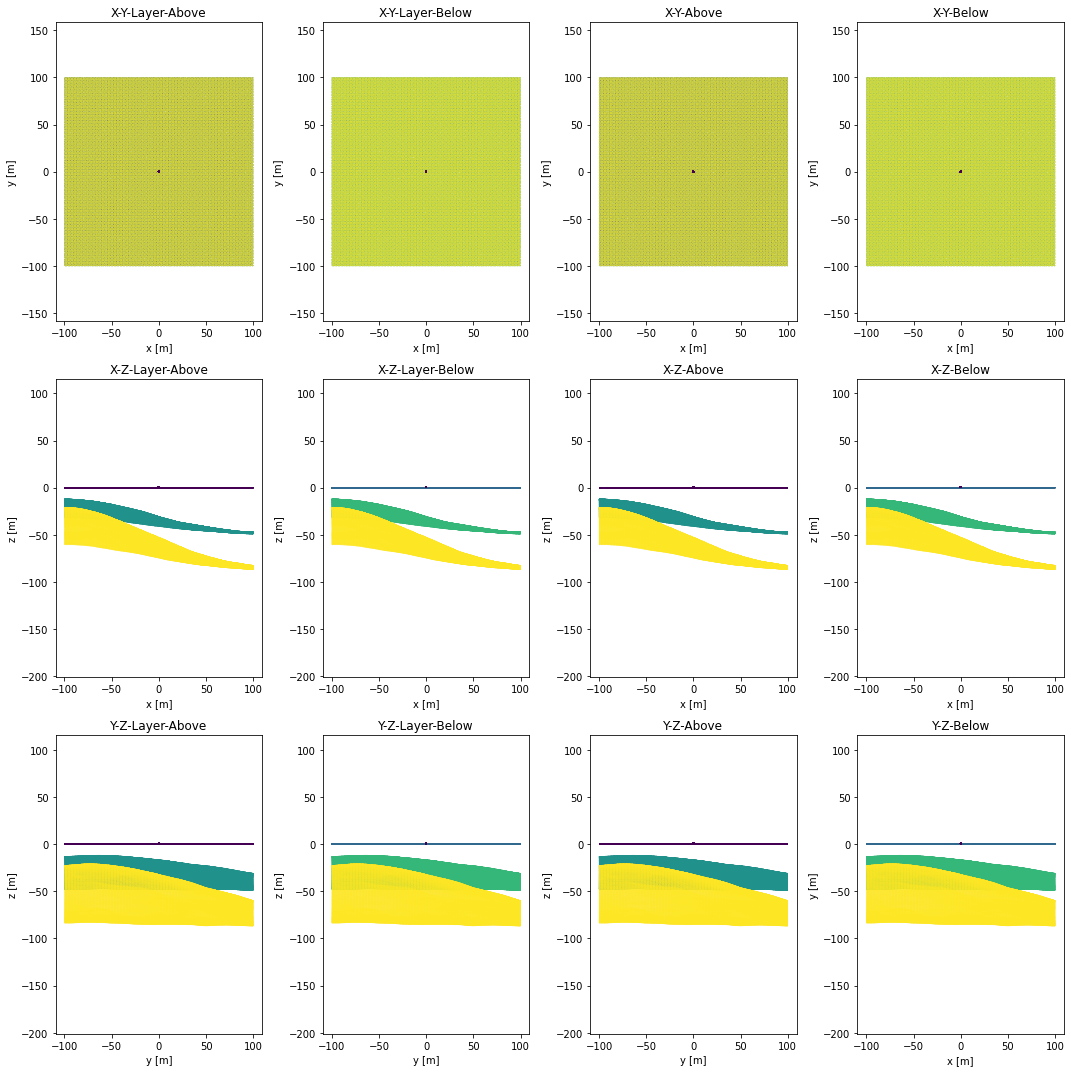

In [58]:
check_setup(v, f, i, s=0.1, layer=None, layer_position=0., cmp='lt', fname=None)

# Position Sweep

In [13]:
SPP = 100
RES = 6

In [14]:
import time
simulation_config = dict()
simulation_config['shots_per_path'] = SPP
simulation_config['max_bounces'] = 100
simulation_config['min_bounces'] = 3
simulation_config['max_attenuation'] = 1e-9
simulation_config['max_propagation_length'] = 1000.
simulation_config['termination_probability'] = 1e-6
simulation_config['min_distance'] = 1e-3
simulation_config['binary_output'] = True
simulation_config['output_all_rays'] = False
simulation_config['seed'] = 0
simulation_config['spheres'] = False

In [15]:
bounds = ((-200, 200.), (-200., 200.))
np.random.seed(0)

o1 = create_flat_interface(bounds, (100, 100), 0, 1, 0, 1, z=0)
o2 = create_flat_interface(bounds, (100, 100), 1, 2, 1, 2, z=-6)

#o2 = create_ellipsoid((0, 0, -4.5), (2., 6., 1.), 1, 2, 1, 2, resolution=3)
#o2 = create_ellipsoid((0, 0, -8), (2., 2., 2.), 1, 2, 1, 2, resolution=4)

#o3 = create_flat_interface(bounds, (100, 100), 1, 0, 1, 0, z=-9)

## RIMFAX
#o1 = create_flat_interface(bounds, (101, 101), 0, 1, 0, 1, z=0)
#o2 = create_ellipsoid((7,-7,-3.5), (5., 8., 1.), 1, 2, 1, 2, resolution=3)

#im = sloped_fractal_surface(2., 4., -8., 5., 70., 0., 25., bounds, dim=(1024,1024))
#o3 = create_rough_interface(im, bounds, 1, 3, 1, 3)
#o3 = simple_assign_materials(o3[0], o3[1], o3[2], 2, 0., 0, 3, op='gt') 
#o3 = simple_assign_layers(o3[0], o3[1], o3[2], 2, 0., 0, 2, op='gt') 

#o1 = create_flat_interface(bounds, (11, 11), 0, 1, 0, 1, z=0.)
#o2 = create_ellipsoid((7,-7,-3.5), (5., 8., 1.), 1, 2, 1, 2, resolution=3)

#im = sloped_fractal_surface(2., 4., -8., 5., 70., 0., 25., bounds, dim=(128,128))
#o3 = create_rough_interface(im, bounds, 1, 3, 1, 3)
#o3 = simple_assign_materials(o3[0], o3[1], o3[2], 2, 0., 0, 3, op='gt')
#o3 = simple_assign_layers(o3[0], o3[1], o3[2], 2, 0., 0, 2, op='gt') 

# iDPR
#o1 = create_flat_interface(bounds, (100, 100), 0, 1, 0, 1, z=0)
#o2 = create_flat_interface(bounds, (100, 100), 1, 2, 1, 2, z=-1.8)

#im2 = sloped_fractal_surface(2., -12., -50., 70., 220., 0., 25, bounds, dim=(1024, 1024))
#o4 = create_rough_interface(im2, bounds, 1, 2, 1, 2)

#im = sloped_fractal_surface(2., -22., -90., 80., 180., 0., 25, bounds, dim=(1024, 1024))
#o3 = create_rough_interface(im, bounds, 2, 3, 2, 3)


In [16]:
materials = np.zeros((4,3))

# permittivities
materials[0, 0] = np.sqrt(1.) # background, above plane
materials[1, 0] = np.sqrt(2.2) # below plane, above_ellipsoid
materials[2, 0] = np.sqrt(10) # below ellipsoid
materials[3, 0] = np.sqrt(6)


materials[:,2] = 0. # all 
materials[0,2] = 0.5 # above_plane
materials[1,2] = 0.5 # below_plane, above_ellipsoid
materials[2,2] = 0. # below_ellipsoid 
materials[3,2] = 0 # below fractal surface

In [17]:
n_samples = 5

source_positions = np.zeros((n_samples, 3), dtype=np.float)
source_positions[:, 0] = np.linspace(-0.5, 0.5, n_samples) # x
source_positions[:, 1] = 0 #9 #np.linspace(-10, 10, 101) # y
source_positions[:, 2] = 0.66 # 0.66 # z

source_positions = tuple([tuple(vec) for vec in source_positions])

In [18]:

#sim_dir = f'SCIENCE_MEETING/real/shallow/SRC_RES_{RES}_SPP_{SPP}'
#sim_dir = f'SCIENCE_MEETING/validation/plane_sphere/SRC_RES_{RES}_SPP_{SPP}'
sim_dir = f'temporary/plane_plane/'

In [19]:
prefix = f'/home/garten/Projekte/Programmierung/simulation_results/{sim_dir}'

In [20]:
simple_source_position_sweep('sweep', [o1, o2], materials, source_positions, src_radius=0.2, src_resolution=RES, 
                      write_obj=False, write=True, prefix=prefix, simulation_config=simulation_config)

100%|██████████| 5/5 [00:00<00:00, 15.60it/s]


## Run em_tracer

In [21]:
# run simulation

import subprocess
from tqdm.notebook import tqdm
for i in tqdm(range(0,n_samples)):
    #print(f'position {i}')
    args = ["/home/garten/Projekte/Programmierung/blazert/cmake-build-release-gcc/examples/em_tracer/src/em_tracer/em_tracer", f'{prefix}/sweep_{i}.json']
    popen = subprocess.Popen(args)
    popen.wait()


  0%|          | 0/5 [00:00<?, ?it/s]

## 